# 7. Persistent Homology Analysis
## Interlaced Texture NCA
### Mia-Katrin Kvalsund
### April 2026


Code to support ALIFE 2026 paper:
 > Stovold, Kvalsund, Ludwig, Sharma, Mordvintsev "Visualising the Attractor Landscape of Neural Cellular Automata"

Based on the Colab notebook developed by Mordvintsev et al. for the ["Growing Neural Cellular Automata"](http://distill.pub/2020/growing-ca) article. and J. Stovold's notebook for the ["Neural Cellular Automata can Respond to Signals"](https://github.com/jstovold/ALIFE2023/blob/master/ExternalSignals.ipynb) article at ALIFE 2023.

Code and materials are restricted for any and all use prior to publication; post-publication the code and associated materials are available under the Apache 2.0 license


In [3]:
import numpy as np
import torch

# Plotting 
import matplotlib.pyplot as plt

# Persistent homology
from ripser import ripser
from persim import plot_diagrams
import gudhi as gd

# Dimensionality reduction
from sklearn.decomposition import PCA

### Load data

In [6]:
data = torch.from_numpy(np.load("data/texture.npy"))

In [22]:
# Permute to tensorflow shape for later plotting and color calculations
B, H, W, C, T = data.shape # James' shape with timesteps at the end
data_3D_big = data.permute(0, 4, 1, 2, 3) # Creates a view, does not bog down memory
data_3D_big = data_3D_big[0]

torch.Size([50, 20, 20, 12])


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.2235294580459595..1.2078431844711304].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.988235354423523..0.9568628072738647].


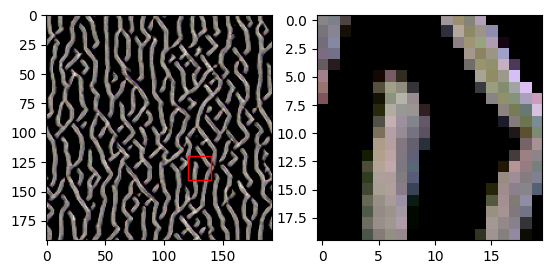

In [24]:
t0, t1 = 0,50# 100, 120
n = 20
rand_x, rand_y = 120,120
data_3D = data_3D_big[t0:t1, rand_x:rand_x+n, rand_y:rand_y+n]
print(data_3D.shape)

plt.figure()
# Check that it looks okay after permuting
plt.subplot(1, 2, 1)
plt.imshow(data_3D_big.numpy()[t1,:,:,:3])
# plot rectangle
rect = plt.Rectangle((rand_y, rand_x), n, n, linewidth=1, edgecolor='r', facecolor='none')
plt.gca().add_patch(rect)

plt.subplot(1, 2, 2)
plt.imshow(data_3D[-1].numpy()[:,:,:3])

# Plot the PH and PCA for timesteps 0-50 and 100-120, subsampled and not, with and without color as part of the state

No section subsample, t0 and t1: 0 50
1843200 3000


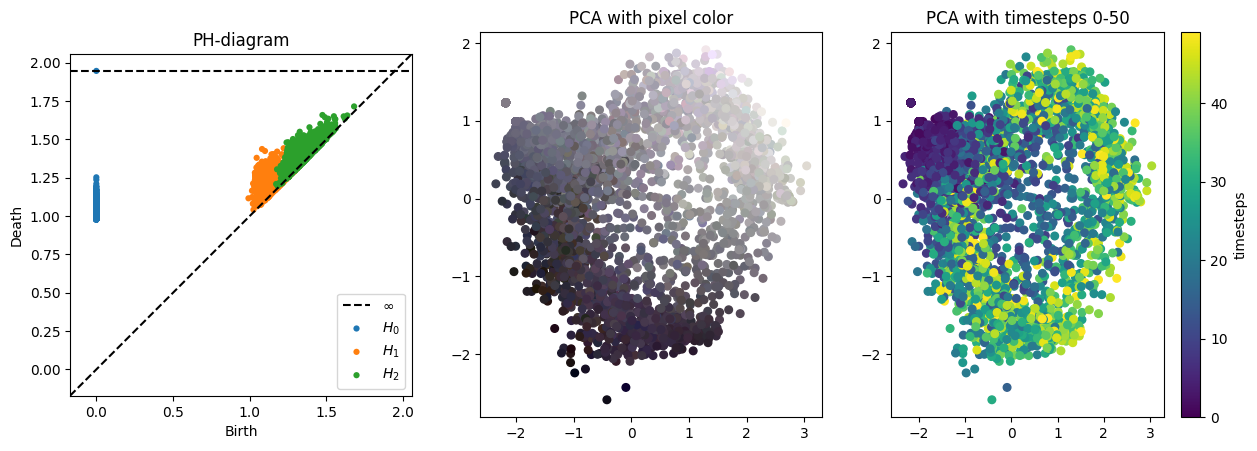

Section subsample, t0 and t1: 0 50
20000 3000


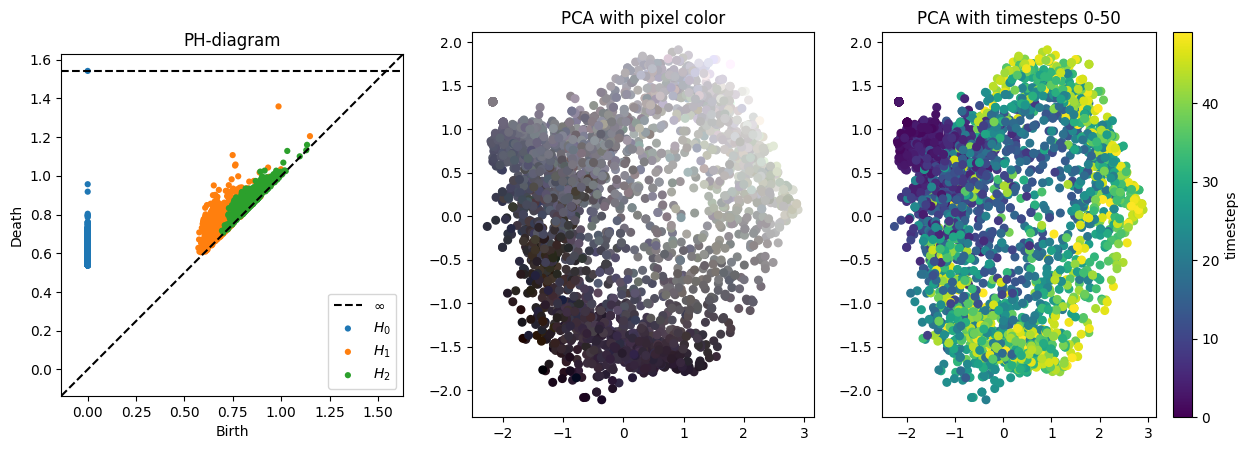

No section subsample, t0 and t1: 100 120
737280 3000


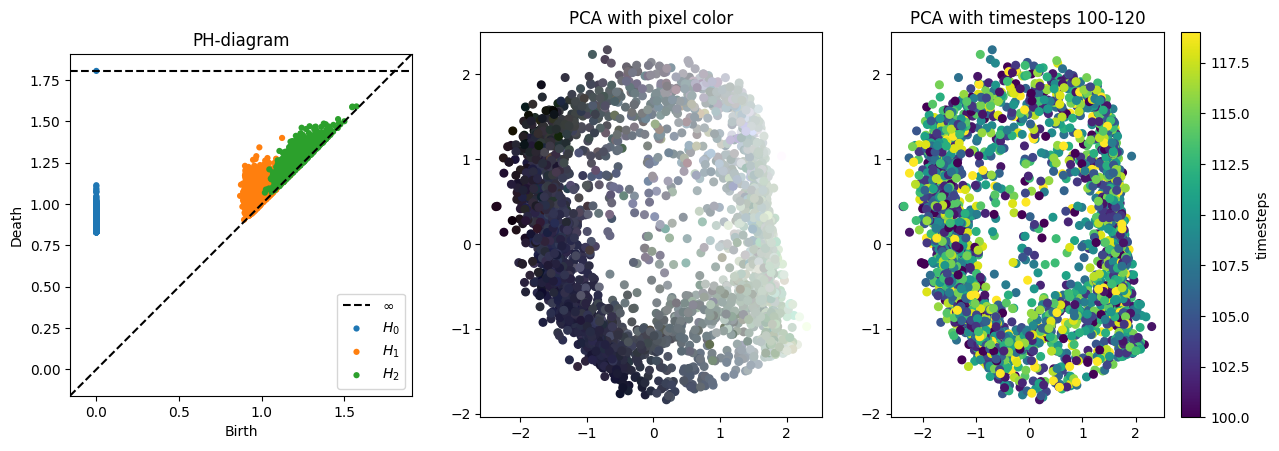

Section subsample, t0 and t1: 100 120
8000 3000


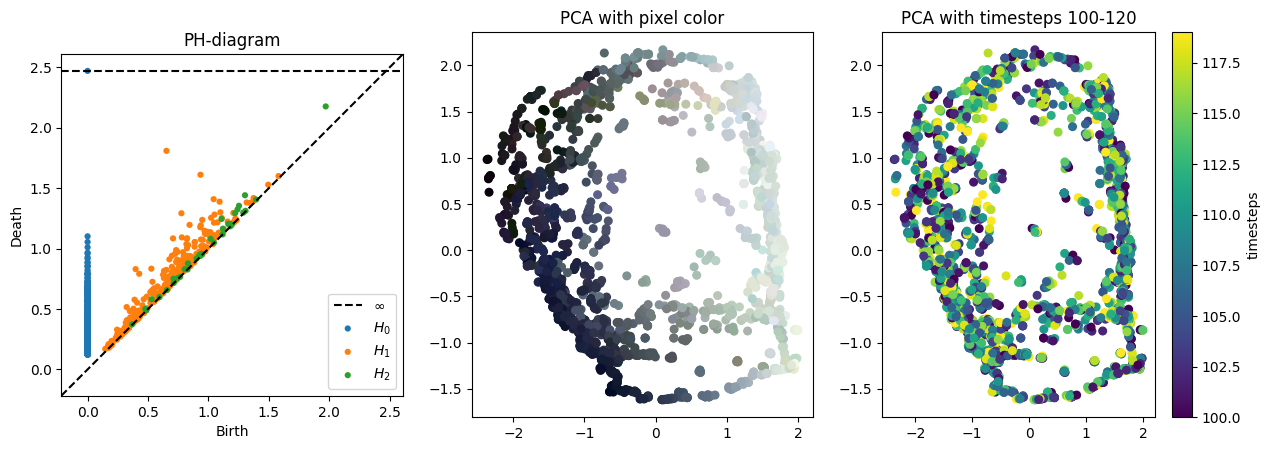

In [40]:
def plot_persistence_and_PCA(data_3D, t0=0, t1=50, diagram_samples=1000, pca_samples=1000, remove_color=True):
    T, n, n, C = data_3D.shape

    flattened_data = data_3D.reshape(-1, C) # Shape (n*n*T, C)
    # Remove color channel from flattened data
    if remove_color:
        flattened_data = flattened_data[:, 3:]

    # Taking care of the diagram
    diagrams = ripser(flattened_data, maxdim=2, metric="euclidean", n_perm=diagram_samples)['dgms']

    # Onto the PCA
    print(flattened_data.shape[0], pca_samples)
    idx_pca = np.random.choice(list(range(flattened_data.shape[0])), size=min(pca_samples, flattened_data.shape[0]), replace=False)
    flattened_data_pca = np.array(flattened_data[idx_pca])

    # Create timesteps
    timesteps = torch.arange(t0, t1).float().unsqueeze(-1).unsqueeze(-1).unsqueeze(-1).repeat(1, n, n, 1)
    timesteps_flat = timesteps.reshape(-1) # Shape (n*n*T, 1)
    timesteps_flat = timesteps_flat[idx_pca]

    colors = data_3D[..., :3]
    flattened_colors = colors.reshape(-1, 3).numpy()
    flattened_colors = flattened_colors[idx_pca]
    flattened_colors = flattened_colors - flattened_colors.min(axis=0, keepdims=True)
    flattened_colors /= flattened_colors.max(axis=0, keepdims=True)

    X2 = PCA(n_components=2).fit_transform(flattened_data_pca)

    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1)
    plt.title("PH-diagram")
    plot_diagrams(diagrams)

    plt.subplot(1, 3, 2)
    plt.title("PCA with pixel color")
    plt.scatter(X2[:, 0], X2[:, 1], s=30, c=flattened_colors)

    plt.subplot(1, 3, 3)
    plt.title(f"PCA with timesteps {t0}-{t1}")
    plt.scatter(X2[:, 0], X2[:, 1], s=30, c=timesteps_flat)
    plt.colorbar(label="timesteps")

    plt.show()

diagram_samples = 1000
pca_samples = 3000
remove_color = False

t0, t1 = 0,50# 100, 120
data_3D_sample = data_3D_big[t0:t1]
print("No section subsample, t0 and t1:", t0, t1)
plot_persistence_and_PCA(data_3D_sample, t0=t0, t1=t1, diagram_samples=diagram_samples, pca_samples=pca_samples, remove_color=remove_color)

n = 20
rand_x, rand_y = 120,120
data_3D_sample = data_3D_big[t0:t1, rand_x:rand_x+n, rand_y:rand_y+n]
print("Section subsample, t0 and t1:", t0, t1)
plot_persistence_and_PCA(data_3D_sample, t0=t0, t1=t1, diagram_samples=diagram_samples, pca_samples=pca_samples, remove_color=remove_color)

t0, t1 = 100, 120
data_3D_sample = data_3D_big[t0:t1]
print("No section subsample, t0 and t1:", t0, t1)
plot_persistence_and_PCA(data_3D_sample, t0=t0, t1=t1, diagram_samples=diagram_samples, pca_samples=pca_samples, remove_color=remove_color)

data_3D_sample = data_3D_big[t0:t1, rand_x:rand_x+n, rand_y:rand_y+n]
print("Section subsample, t0 and t1:", t0, t1)
plot_persistence_and_PCA(data_3D_sample, t0=t0, t1=t1, diagram_samples=diagram_samples, pca_samples=pca_samples, remove_color=remove_color)


No section subsample, t0 and t1: 0 50
1843200 3000


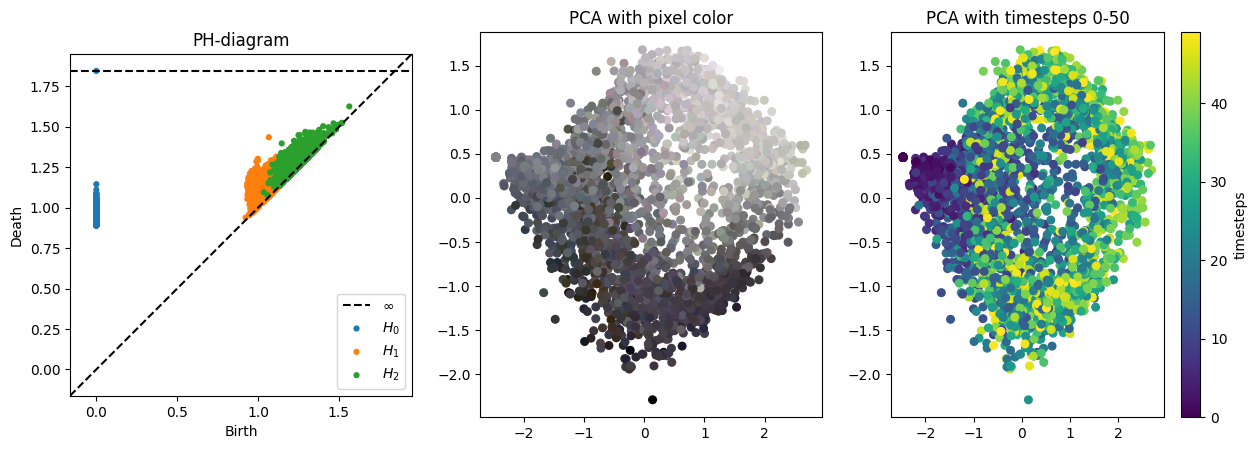

Section subsample, t0 and t1: 0 50
20000 3000


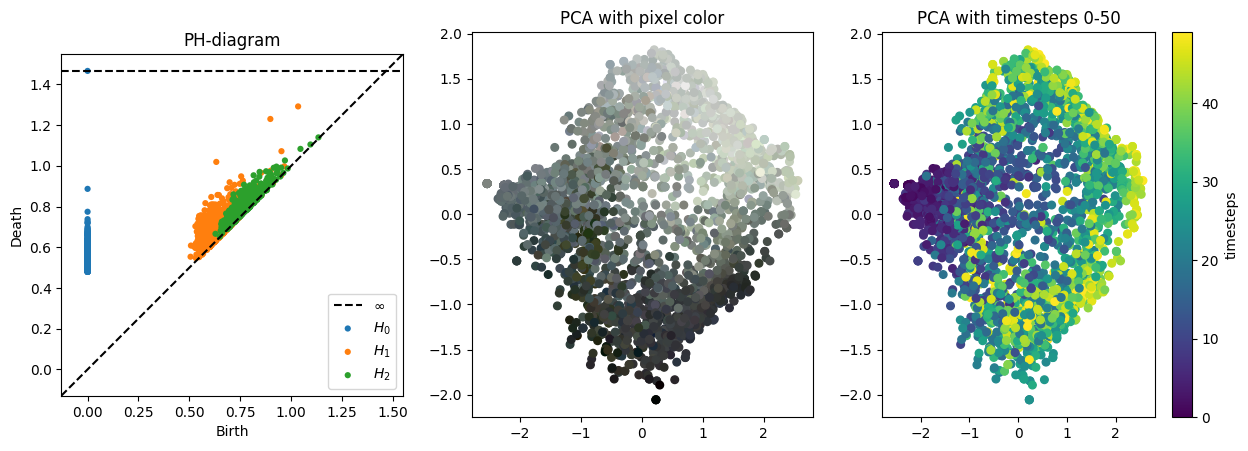

No section subsample, t0 and t1: 100 120
737280 3000


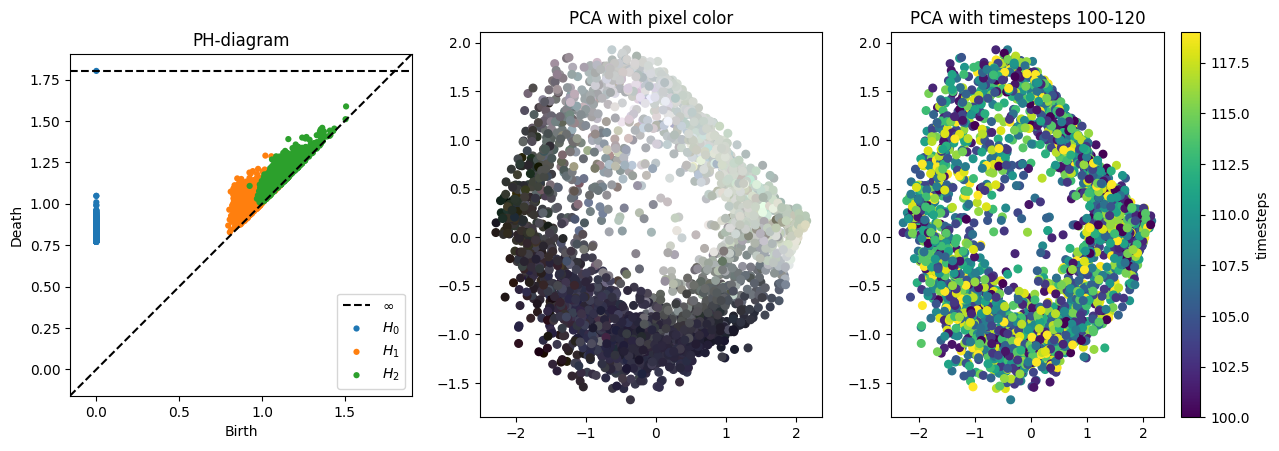

Section subsample, t0 and t1: 100 120
8000 3000


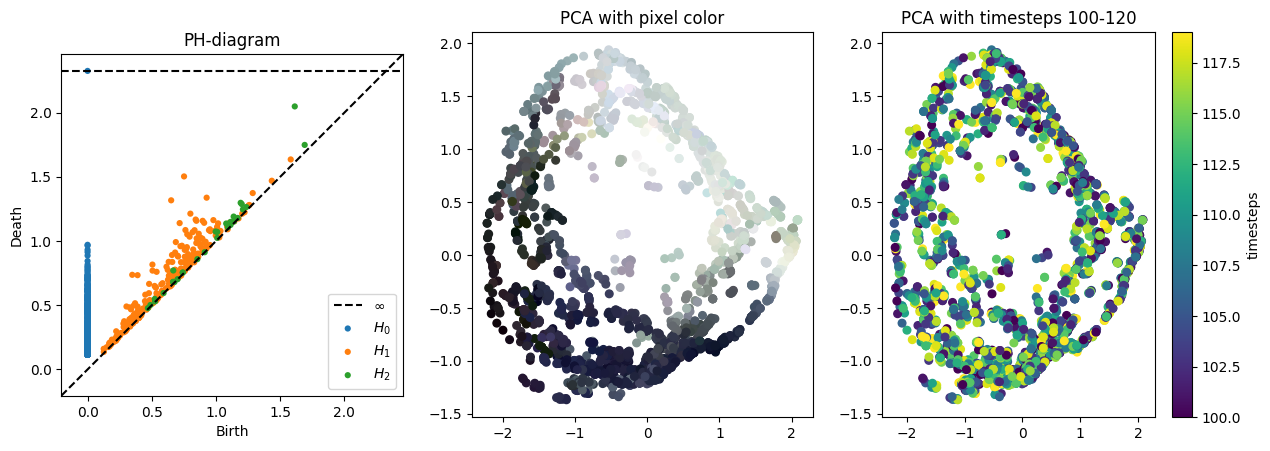

In [41]:
diagram_samples = 1000
pca_samples = 3000
remove_color = True

t0, t1 = 0,50# 100, 120
data_3D_sample = data_3D_big[t0:t1]
print("No section subsample, t0 and t1:", t0, t1)
plot_persistence_and_PCA(data_3D_sample, t0=t0, t1=t1, diagram_samples=diagram_samples, pca_samples=pca_samples, remove_color=remove_color)

n = 20
rand_x, rand_y = 120,120
data_3D_sample = data_3D_big[t0:t1, rand_x:rand_x+n, rand_y:rand_y+n]
print("Section subsample, t0 and t1:", t0, t1)
plot_persistence_and_PCA(data_3D_sample, t0=t0, t1=t1, diagram_samples=diagram_samples, pca_samples=pca_samples, remove_color=remove_color)

t0, t1 = 100, 120
data_3D_sample = data_3D_big[t0:t1]
print("No section subsample, t0 and t1:", t0, t1)
plot_persistence_and_PCA(data_3D_sample, t0=t0, t1=t1, diagram_samples=diagram_samples, pca_samples=pca_samples, remove_color=remove_color)

data_3D_sample = data_3D_big[t0:t1, rand_x:rand_x+n, rand_y:rand_y+n]
print("Section subsample, t0 and t1:", t0, t1)
plot_persistence_and_PCA(data_3D_sample, t0=t0, t1=t1, diagram_samples=diagram_samples, pca_samples=pca_samples, remove_color=remove_color)

In [53]:
image_size = data_3D_big.shape[1] * data_3D_big.shape[2]
subsample_image_size = n * n

print(
    "For the first 50 timesteps, we have", image_size*50, 
    "points and sample", np.round(diagram_samples*100/(image_size*50), 3), 
    "% of them for the PH-analysis")

print(
    "When subsampling, we have", subsample_image_size*50, 
    "points and sample", np.round(diagram_samples*100/(subsample_image_size*50), 3), 
    "% of them for the PH-analysis")

print(
    "\nFor timesteps 100 to 120, we have", image_size*20, 
    "points and sample", np.round(diagram_samples*100/(image_size*20), 3), 
    "% of them for the PH-analysis")

print(
    "When subsampling, we have", subsample_image_size*20, 
    "points and sample", np.round(diagram_samples*100/(subsample_image_size*20), 3), 
    "% of them for the PH-analysis")


For the first 50 timesteps, we have 1843200 points and sample 0.054 % of them for the PH-analysis
When subsampling, we have 20000 points and sample 5.0 % of them for the PH-analysis

For timesteps 100 to 120, we have 737280 points and sample 0.136 % of them for the PH-analysis
When subsampling, we have 8000 points and sample 12.5 % of them for the PH-analysis
